# Week10 - Dasar-Dasar Deteksi Obyek
Praktikum Pengolahan Citra dan Visi Komputer (Modul 10)

**D1.** Deteksi Obyek Dasar (soal 1-7) | **D2.** Feature Matching dan Face Detection (soal 8-14) | **D3.** Pengayaan CNN

Sebelum menjalankan: ubah `BASE` pada sel pengaturan path agar sesuai posisi folder gambar di Google Drive masing-masing.

## D1. Praktikum Deteksi Obyek Dasar
### 1. Import library dan akses Drive

In [1]:
# import library yang dibutuhkan
import os, glob
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# akses drive
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
# ===== SESUAIKAN PATH FOLDER MASING-MASING =====
BASE    = '/content/drive/MyDrive/KULIAH/PCVK/Images'   # folder gambar praktikum

def path(*p):
    return os.path.join(BASE, *p)

def baca_rgb(file):
    # baca gambar berwarna dan ubah ke RGB agar benar saat ditampilkan matplotlib
    img = cv.imread(file)
    if img is None:
        raise FileNotFoundError('Gambar tidak ditemukan: ' + file)
    return cv.cvtColor(img, cv.COLOR_BGR2RGB)

def baca_gray(file):
    img = cv.imread(file, 0)
    if img is None:
        raise FileNotFoundError('Gambar tidak ditemukan: ' + file)
    return img

def tampil(img, judul='', ukuran=(8, 6)):
    plt.figure(figsize=ukuran)
    plt.imshow(img, cmap='gray') if img.ndim == 2 else plt.imshow(img)
    plt.title(judul)
    plt.show()

def pasangan(kiri, kanan, judul_kiri='', judul_kanan='', ukuran=(14, 6)):
    plt.figure(figsize=ukuran)
    plt.subplot(121); plt.imshow(kiri, cmap='gray' if kiri.ndim == 2 else None); plt.title(judul_kiri)
    plt.subplot(122); plt.imshow(kanan, cmap='gray' if kanan.ndim == 2 else None); plt.title(judul_kanan)
    plt.show()

### 2. Template Matching (6 metode OpenCV)
Memakai `cv.matchTemplate()` dengan gambar `cats_and_bunnies.jpg` dan citra template kucing (`cat2_template.jpg`).

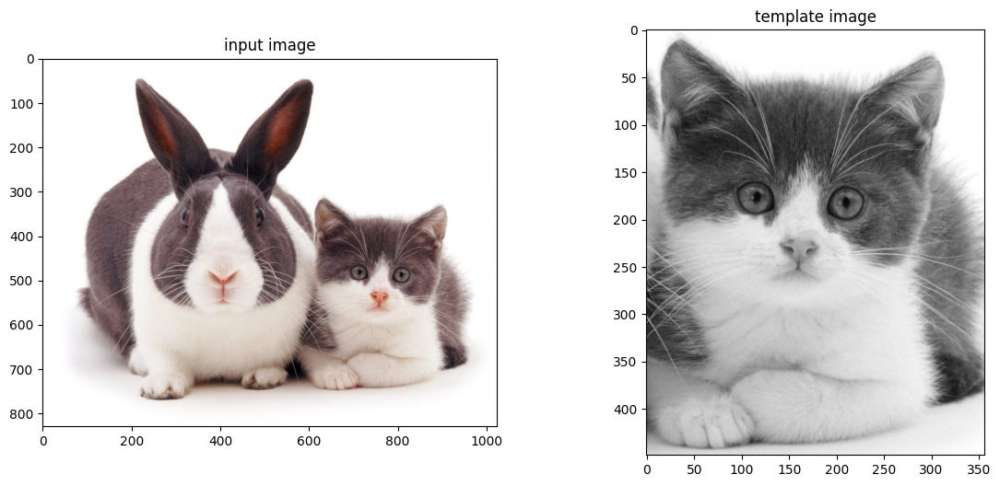

In [17]:
BASE = '/content/drive/MyDrive/KULIAH/PCVK/Images'
TEMPLATE_FILE = 'cat2_templatejpg.jpg'

img_rgb  = baca_rgb(path('cats_and_bunnies.jpg'))
img_gray = cv.cvtColor(img_rgb, cv.COLOR_RGB2GRAY)
templ    = baca_gray(path(TEMPLATE_FILE))
h, w     = templ.shape

pasangan(img_rgb, templ, 'input image', 'template image')

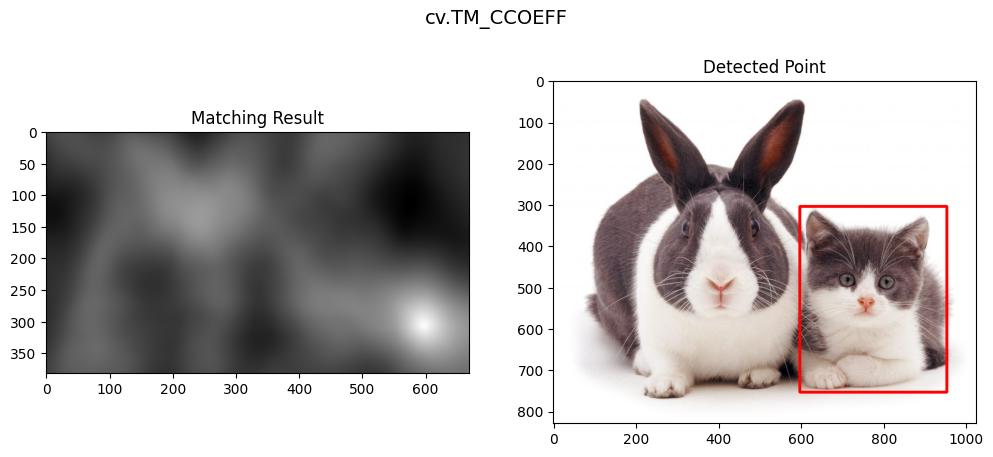

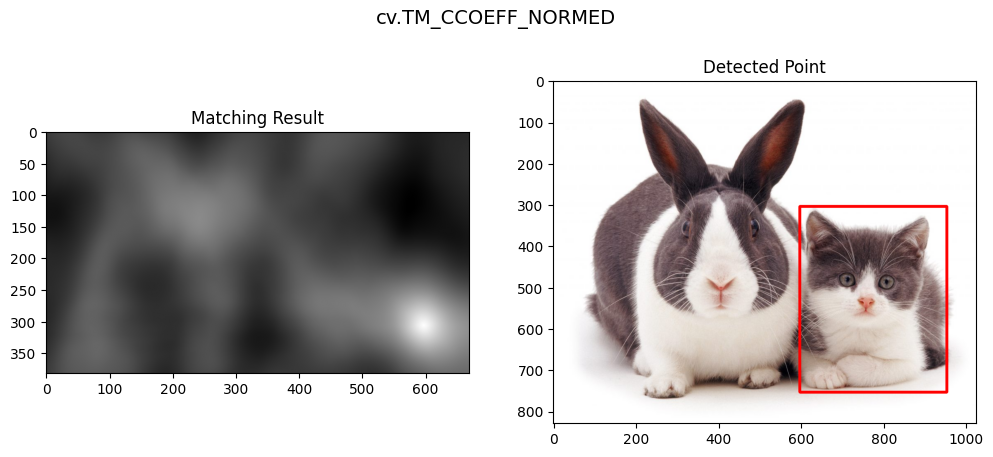

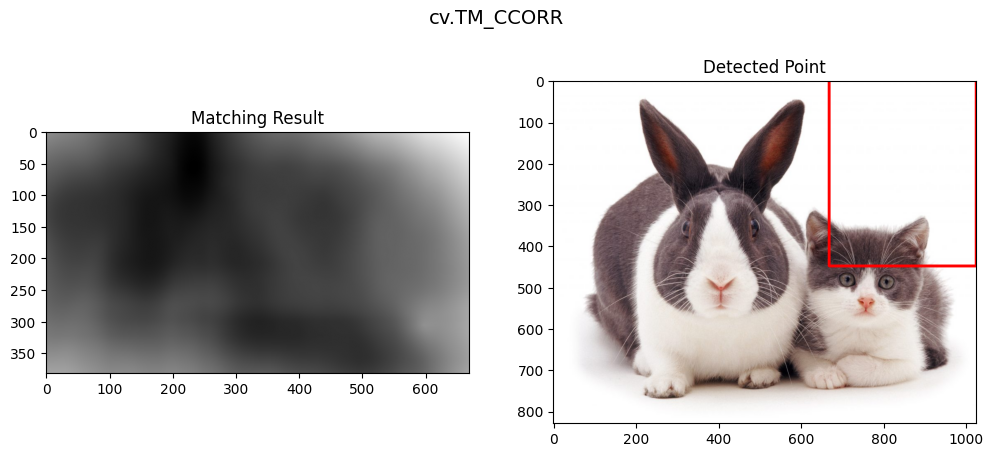

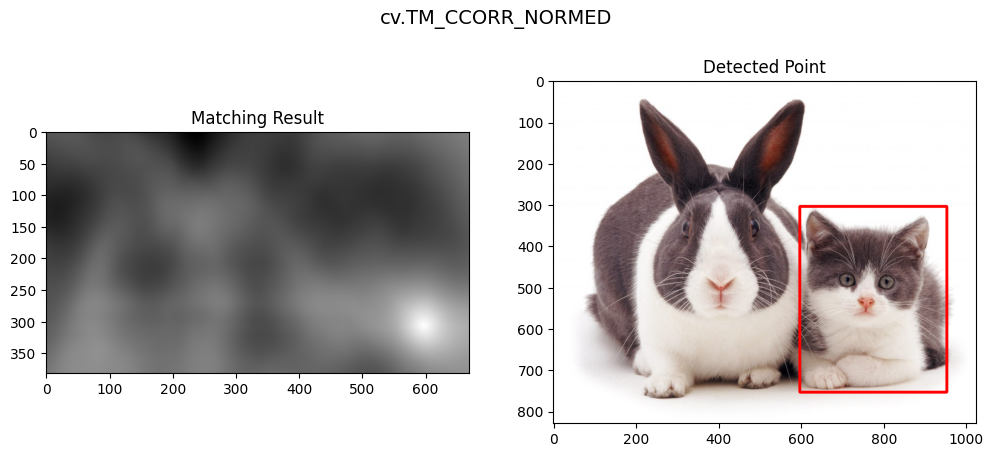

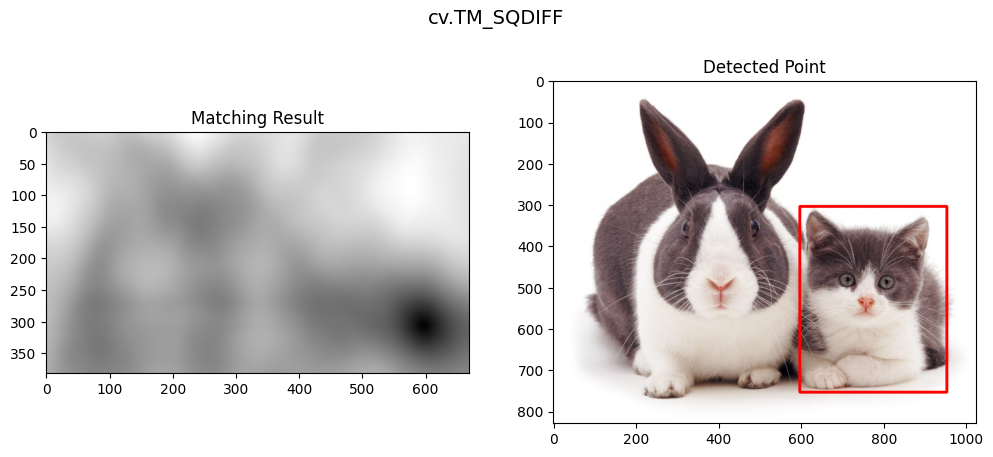

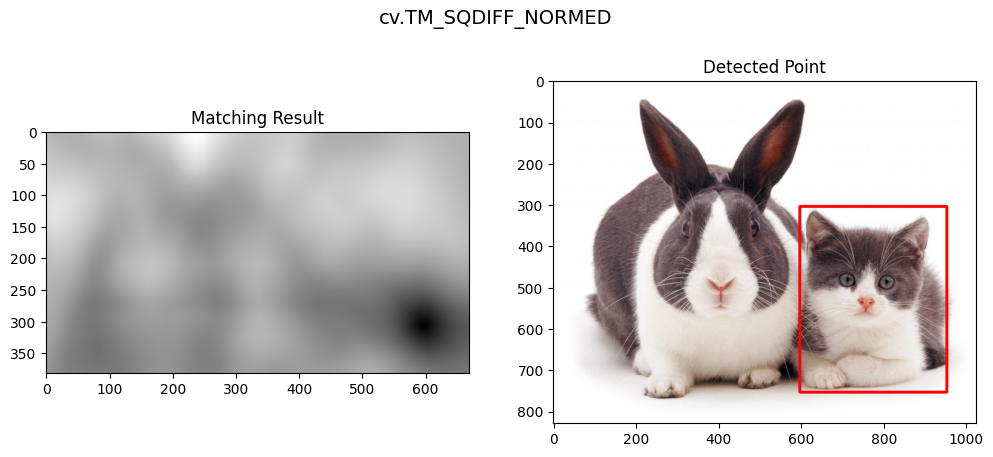

In [18]:
metode = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED',
          'cv.TM_CCORR',  'cv.TM_CCORR_NORMED',
          'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

for nama in metode:
    m = getattr(cv, nama.split('.')[1])
    res = cv.matchTemplate(img_gray, templ, m)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    # SQDIFF: nilai terkecil = paling cocok, metode lain: nilai terbesar
    if m in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)

    hasil = img_rgb.copy()
    cv.rectangle(hasil, top_left, bottom_right, (255, 0, 0), 5)

    plt.figure(figsize=(12, 5))
    plt.suptitle(nama, fontsize=14)
    plt.subplot(121); plt.imshow(res, cmap='gray'); plt.title('Matching Result')
    plt.subplot(122); plt.imshow(hasil);            plt.title('Detected Point')
    plt.show()

### 3. Template Matching tanpa OpenCV (multiple object)
Memakai Normalized Cross-Correlation (zero-mean) yang dihitung manual dengan NumPy, lalu non-maximum suppression untuk mengambil banyak objek. Gambar dibaca dengan PIL dan digambar dengan matplotlib (tanpa OpenCV).

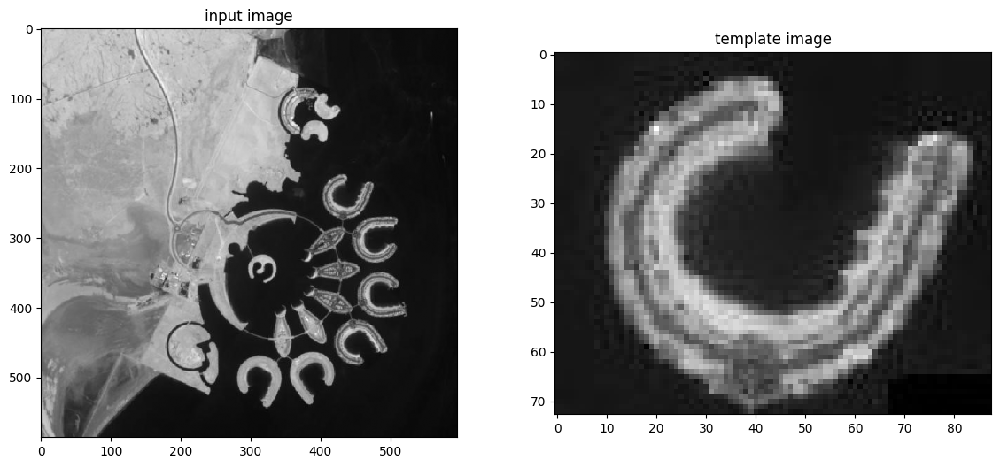

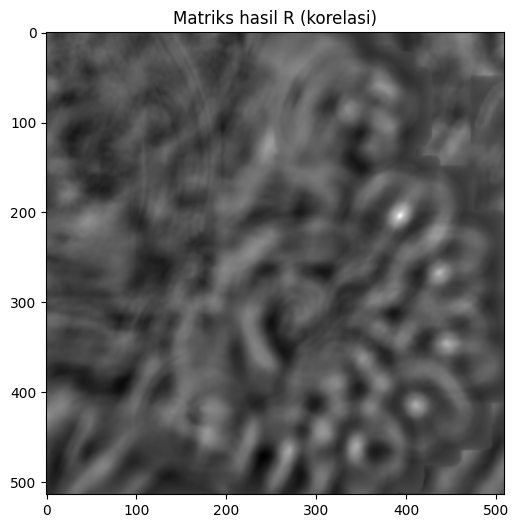

In [19]:
from PIL import Image
from numpy.lib.stride_tricks import sliding_window_view
import matplotlib.patches as patches

I = np.array(Image.open(path('bahrain.jpg')).convert('L'), dtype=np.float32)
T = np.array(Image.open(path('bahrain-template.jpg')).convert('L'), dtype=np.float32)
th, tw = T.shape

def ncc_map(I, T):
    # matriks R: korelasi ternormalisasi template T pada setiap posisi (y, x) citra I
    th, tw = T.shape
    Tz = T - T.mean()
    Tn = np.sqrt((Tz ** 2).sum())
    H, W = I.shape
    R = np.zeros((H - th + 1, W - tw + 1), dtype=np.float32)
    for y in range(H - th + 1):
        strip = I[y:y + th, :]
        win = sliding_window_view(strip, (th, tw))[0]          # (jumlah_x, th, tw)
        win = win - win.mean(axis=(1, 2), keepdims=True)
        num = (win * Tz).sum(axis=(1, 2))
        den = np.sqrt((win ** 2).sum(axis=(1, 2))) * Tn + 1e-8
        R[y] = num / den
    return R

R = ncc_map(I, T)

pasangan(I, T, 'input image', 'template image')
tampil(R, 'Matriks hasil R (korelasi)')

Jumlah objek terdeteksi: 3


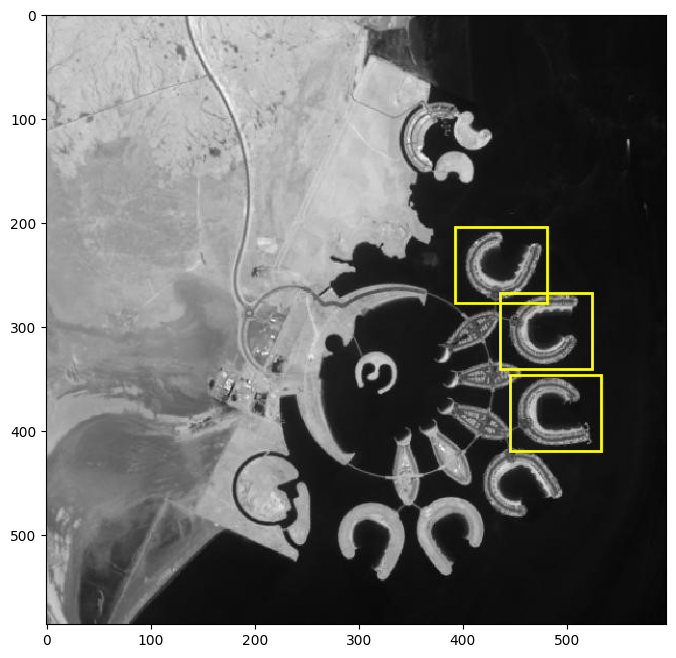

In [20]:
THRESHOLD = 0.5   # ubah (0-1) bila objek yang terdeteksi kurang/berlebih

R_kerja = R.copy()
lokasi = []
while True:
    y, x = np.unravel_index(np.argmax(R_kerja), R_kerja.shape)
    if R_kerja[y, x] < THRESHOLD:
        break
    lokasi.append((x, y, R_kerja[y, x]))
    # buang area sekitar titik terpilih (non-maximum suppression)
    R_kerja[max(0, y - th // 2): y + th // 2 + 1,
            max(0, x - tw // 2): x + tw // 2 + 1] = -1

print('Jumlah objek terdeteksi:', len(lokasi))

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(I, cmap='gray')
for (x, y, skor) in lokasi:
    ax.add_patch(patches.Rectangle((x, y), tw, th, linewidth=2, edgecolor='yellow', facecolor='none'))
plt.show()

### 4. Edge Detection: Sobel, Canny, Laplacian
Gambar: `car-park.jpg`

In [21]:
img  = baca_rgb(path('car-park.jpg'))
gray = cv.cvtColor(img, cv.COLOR_RGB2GRAY)
blur = cv.GaussianBlur(gray, (5, 5), 0)   # haluskan dulu untuk mengurangi noise

a. Sobel Edge Detection


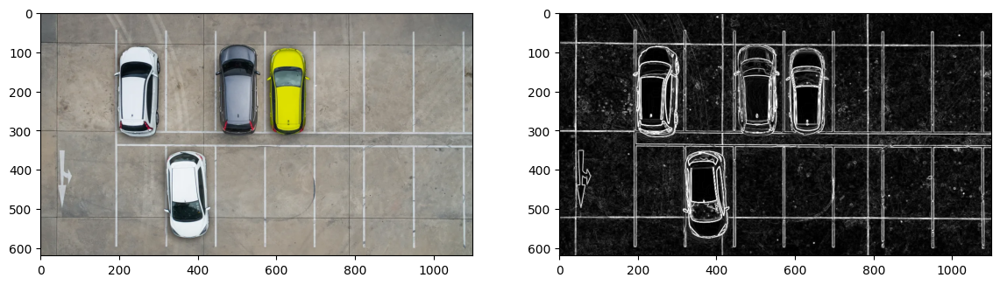

In [22]:
# a. Sobel Edge Detection
sobel_x = cv.Sobel(gray, cv.CV_64F, 1, 0, ksize=3)
sobel_y = cv.Sobel(gray, cv.CV_64F, 0, 1, ksize=3)
sobel   = cv.convertScaleAbs(cv.magnitude(sobel_x, sobel_y))

print('a. Sobel Edge Detection')
pasangan(img, sobel)

b. Canny Edge Detection


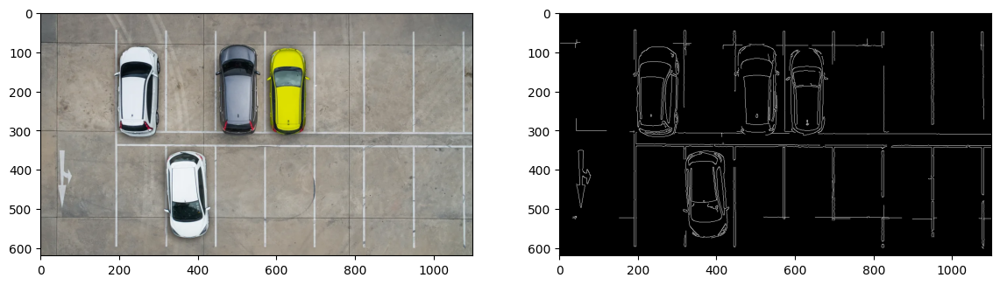

In [23]:
# b. Canny Edge Detection
canny = cv.Canny(blur, 100, 200)

print('b. Canny Edge Detection')
pasangan(img, canny)

c. Laplacian Edge Detection


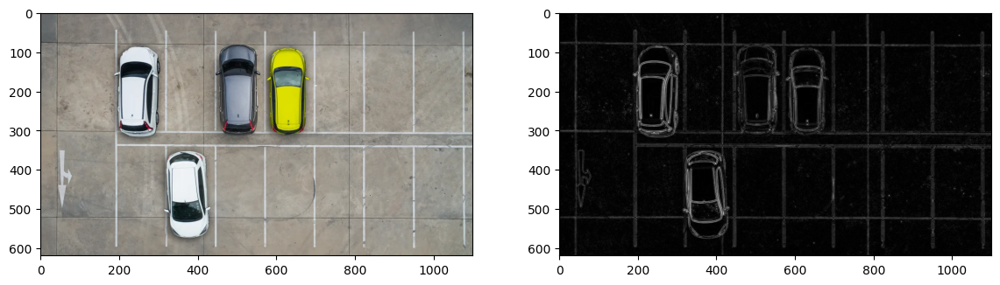

In [24]:
# c. Laplacian Edge Detection
laplacian = cv.convertScaleAbs(cv.Laplacian(blur, cv.CV_64F, ksize=3))

print('c. Laplacian Edge Detection')
pasangan(img, laplacian)

### 5. Corner Detection: Harris dan Shi-Tomasi
Gambar: `chess-board.jpg`

a. Harris Corner Detection


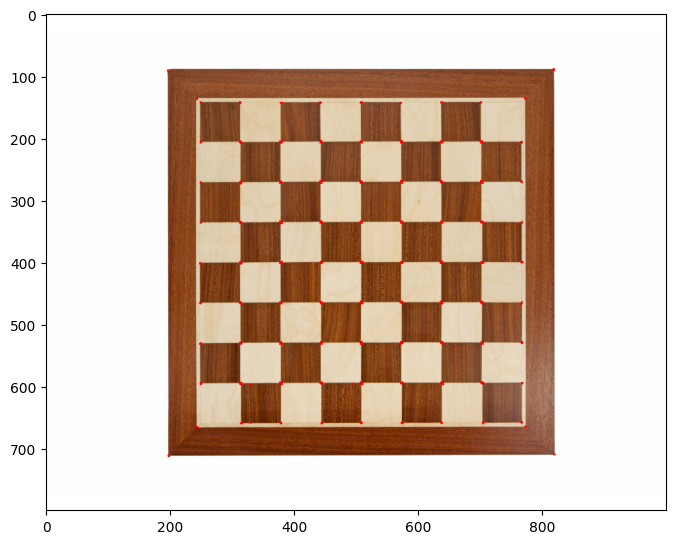

In [25]:
img  = baca_rgb(path('chess-board.jpg'))
gray = cv.cvtColor(img, cv.COLOR_RGB2GRAY)

# a. Harris Corner Detection
dst = cv.cornerHarris(np.float32(gray), 2, 3, 0.04)
dst = cv.dilate(dst, None)
harris = img.copy()
harris[dst > 0.01 * dst.max()] = [255, 0, 0]      # titik sudut diberi warna merah

print('a. Harris Corner Detection')
tampil(harris, '', ukuran=(8, 8))

b. Shi-Tomasi Corner Detection


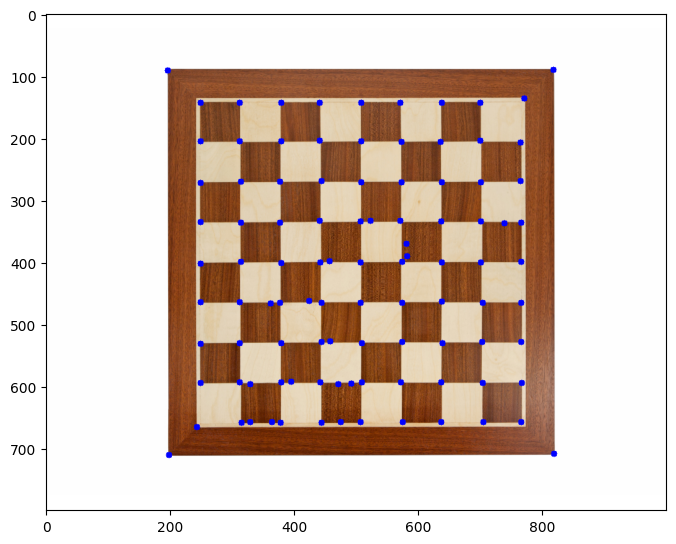

In [26]:
# b. Shi-Tomasi Corner Detection
corners = cv.goodFeaturesToTrack(gray, 100, 0.01, 10)   # (jumlah sudut, quality level, jarak minimum)
corners = np.int32(corners)

shitomasi = img.copy()
for c in corners:
    x, y = c.ravel()
    cv.circle(shitomasi, (int(x), int(y)), 5, (0, 0, 255), -1)

print('b. Shi-Tomasi Corner Detection')
tampil(shitomasi, '', ukuran=(8, 8))

### 6. Grid Detection dengan Hough Transform
Gambar: `sudoku.jpg`. Tahapan: Canny, dilasi, erosi, `cv2.HoughLines()`, lalu gabungkan garis yang mirip.

In [37]:
# img  = baca_rgb(path('sudoku.jpg'))
# gray = cv.cvtColor(img, cv.COLOR_RGB2GRAY)
# blur = cv.GaussianBlur(gray, (5, 5), 0)

# # 1. Canny Edge Detection
# edges = cv.Canny(blur, 50, 150)

# # 2. Dilasi (menyatukan dua tepi pemisah grid)
# kernel = np.ones((3, 3), np.uint8)
# dilasi = cv.dilate(edges, kernel, iterations=1)

# # 3. Erosi (menipiskan kembali garis yang menebal)
# erosi = cv.erode(dilasi, kernel, iterations=1)

# # 4. Hough Lines
# lines = cv.HoughLines(erosi, 1, np.pi / 180, 100)   # ubah threshold (100) bila garis terlalu sedikit/banyak
# print('Jumlah garis sebelum digabung:', 0 if lines is None else len(lines))

Jumlah garis sebelum digabung: 2941


In [41]:
import cv2 as cv
import numpy as np

img  = baca_rgb(path('sudoku.jpg'))
gray = cv.cvtColor(img,cv.COLOR_BGR2GRAY)
edges = cv.Canny(gray,50,150,apertureSize = 3)

lines = cv.HoughLines(edges,1,np.pi/180,200)
for line in lines:
    rho,theta = line[0]
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a*rho
    y0 = b*rho
    x1 = int(x0 + 1000*(-b))
    y1 = int(y0 + 1000*(a))
    x2 = int(x0 - 1000*(-b))
    y2 = int(y0 - 1000*(a))

    cv.line(img,(x1,y1),(x2,y2),(0,0,255),2)

cv.imwrite('houghlines3.jpg',img)

True

In [42]:
import cv2 as cv
import numpy as np

img  = baca_rgb(path('sudoku.jpg'))
gray = cv.cvtColor(img,cv.COLOR_BGR2GRAY)
edges = cv.Canny(gray,50,150,apertureSize = 3)
lines = cv.HoughLinesP(edges,1,np.pi/180,100,minLineLength=100,maxLineGap=10)
for line in lines:
    x1,y1,x2,y2 = line[0]
    cv.line(img,(x1,y1),(x2,y2),(0,255,0),2)

cv.imwrite('houghlines5.jpg',img)

True

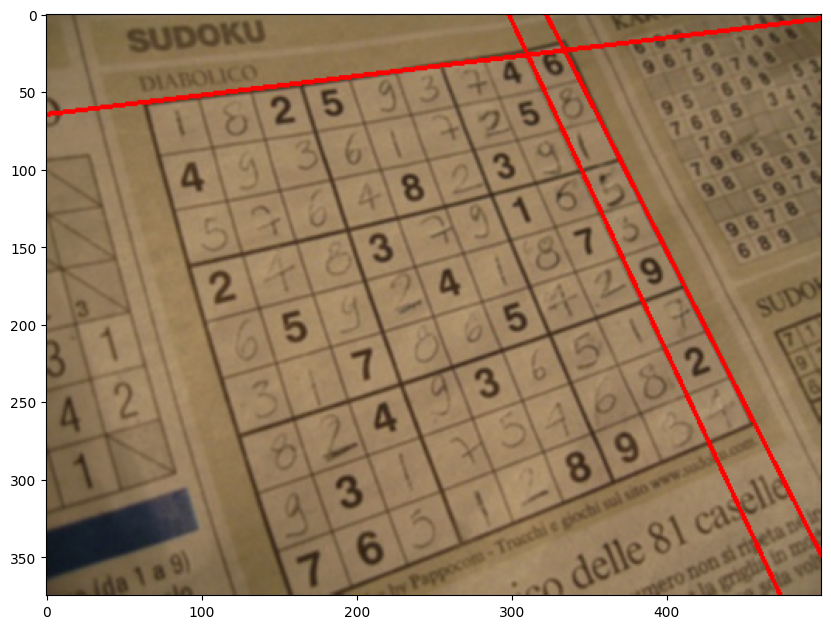

In [43]:
img  = baca_rgb(path('sudoku.jpg'))
gray = cv.cvtColor(img, cv.COLOR_RGB2GRAY)
edges = cv.Canny(gray, 50, 150, apertureSize=3)

lines = cv.HoughLines(edges, 1, np.pi/180, 200)
for line in lines:
    rho, theta = line[0]
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a*rho
    y0 = b*rho
    x1 = int(x0 + 1000*(-b))
    y1 = int(y0 + 1000*(a))
    x2 = int(x0 - 1000*(-b))
    y2 = int(y0 - 1000*(a))
    cv.line(img, (x1, y1), (x2, y2), (255, 0, 0), 2)

plt.figure(figsize=(10, 8))
plt.imshow(img)
plt.show()

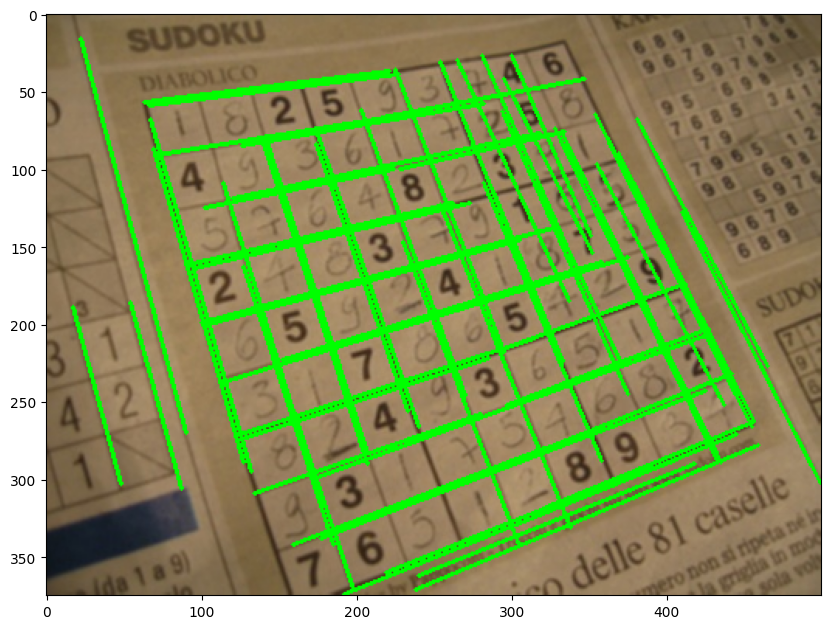

In [44]:
img  = baca_rgb(path('sudoku.jpg'))
gray = cv.cvtColor(img, cv.COLOR_RGB2GRAY)
edges = cv.Canny(gray, 50, 150, apertureSize=3)

lines = cv.HoughLinesP(edges, 1, np.pi/180, 100, minLineLength=100, maxLineGap=10)
for line in lines:
    x1, y1, x2, y2 = line[0]
    cv.line(img, (x1, y1), (x2, y2), (0, 255, 0), 2)

plt.figure(figsize=(10, 8))
plt.imshow(img)
plt.show()

### 7. Contour Detection dengan `findContours()`
Gambar: `laptop.jpg`

Jumlah kontur: 419


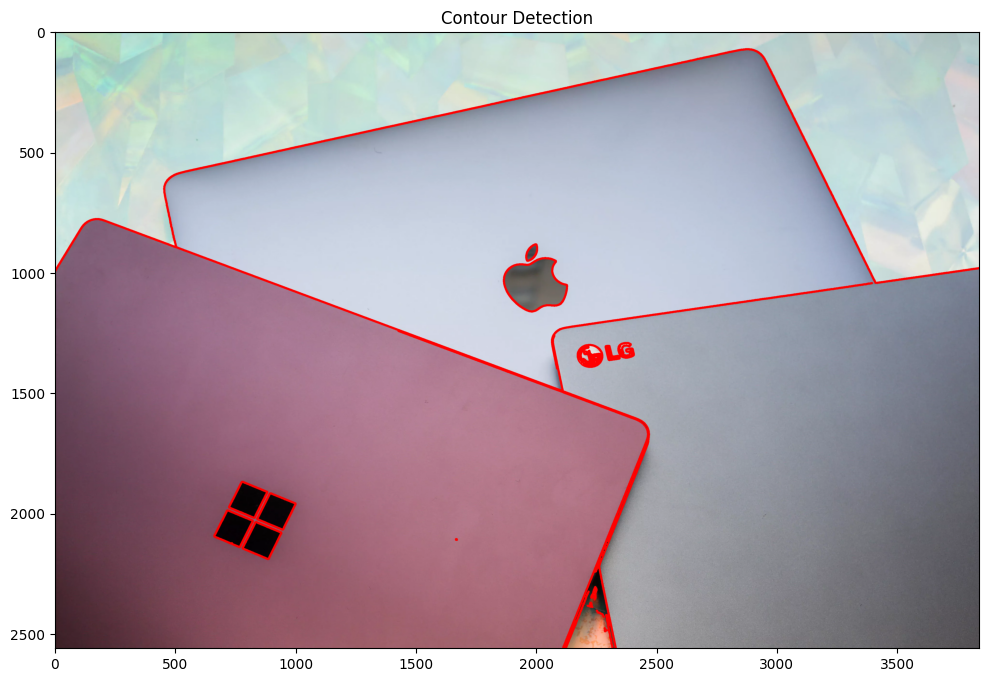

In [29]:
img  = baca_rgb(path('laptop.jpg'))
gray = cv.cvtColor(img, cv.COLOR_RGB2GRAY)
blur = cv.GaussianBlur(gray, (7, 7), 0)

# 1. ubah menjadi citra biner (Canny edge detection)
biner = cv.Canny(blur, 30, 100)
biner = cv.dilate(biner, np.ones((3, 3), np.uint8), iterations=1)

# 2. temukan kontur
contours, hierarchy = cv.findContours(biner, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)
print('Jumlah kontur:', len(contours))

# 3. gambar kontur pada citra input
hasil = img.copy()
cv.drawContours(hasil, contours, -1, (255, 0, 0), 5)
tampil(hasil, 'Contour Detection', ukuran=(12, 8))

## D2. Praktikum Feature Matching dan Face Detection
### Feature Matching: ORB dan SIFT (reeses_puffs dan many_cereals)
Bagian ini dari ulasan teori C.2.1 (dipakai juga untuk soal 14c).

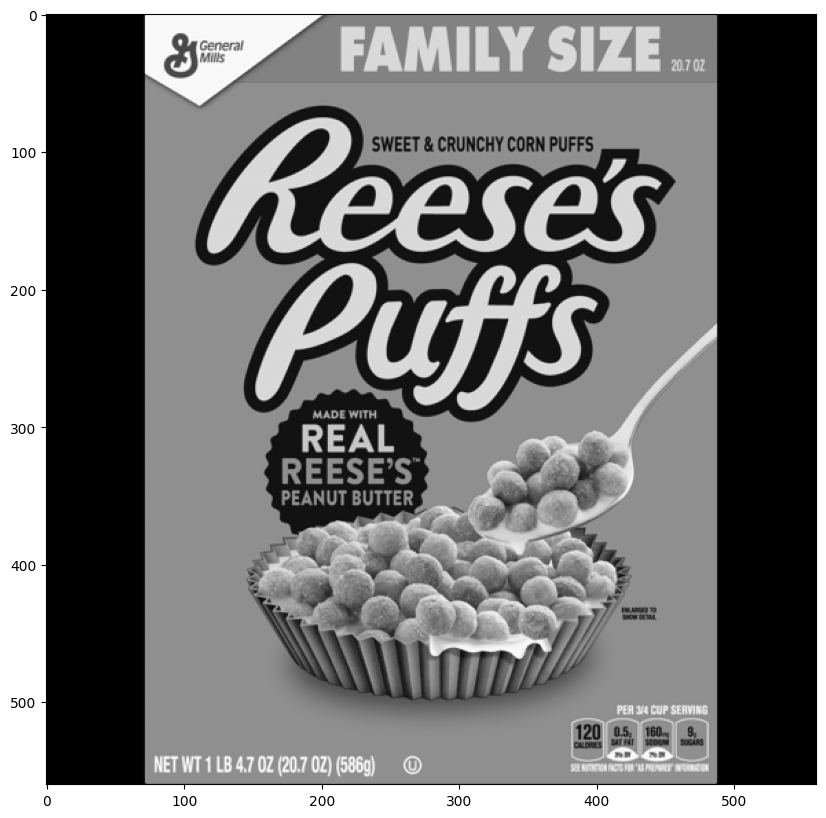

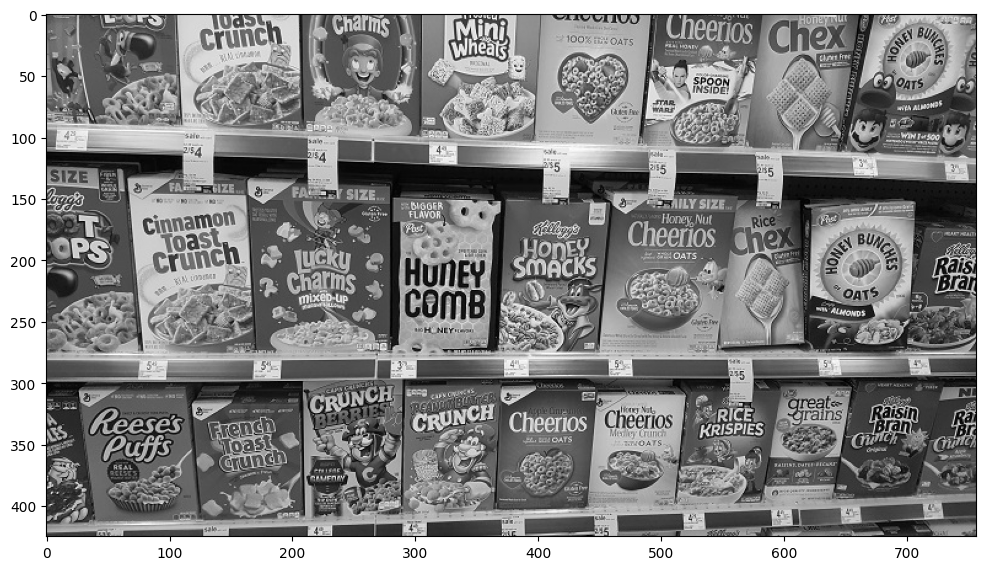

In [32]:
def display(img, cmap='gray', ukuran=(12, 10)):
    fig = plt.figure(figsize=ukuran)
    ax = fig.add_subplot(111)
    ax.imshow(img, cmap=cmap)
    plt.show()

reeses  = cv.imread(path('reeses_puffs.png'), 0)
cereals = cv.imread(path('many_cereals.jpg'), 0)
display(reeses)
display(cereals)

jarak match pertama: 71.0
jumlah match: 139


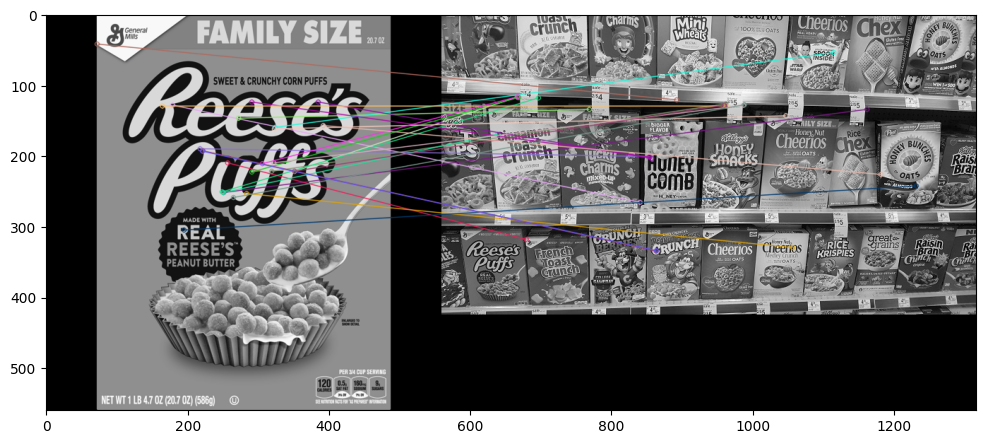

In [33]:
# Brute-Force Matching dengan ORB Descriptor
orb = cv.ORB_create()
kp1, des1 = orb.detectAndCompute(reeses, None)
kp2, des2 = orb.detectAndCompute(cereals, None)

bf = cv.BFMatcher(cv.NORM_HAMMING, crossCheck=True)
matches = bf.match(des1, des2)
print('jarak match pertama:', matches[0].distance)
print('jumlah match:', len(matches))

matches = sorted(matches, key=lambda x: x.distance)
reeses_match = cv.drawMatches(reeses, kp1, cereals, kp2, matches[:25], None, flags=2)
display(reeses_match)

In [ ]:
# Brute-Force Matching dengan SIFT Descriptor dan Ratio Test
sift = cv.SIFT_create()      # jika error: !pip install -U opencv-python lalu restart runtime
kp1, des1 = sift.detectAndCompute(reeses, None)
kp2, des2 = sift.detectAndCompute(cereals, None)

bf = cv.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

good = []
# makin kecil jarak makin cocok; ratio test: jarak match1 < 75% jarak match2
for match1, match2 in matches:
    if match1.distance < 0.75 * match2.distance:
        good.append([match1])

print('jumlah good match:', len(good), 'dari', len(matches))

sift_matches = cv.drawMatchesKnn(reeses, kp1, cereals, kp2, good, None, flags=2)
display(sift_matches)

### 8. Face Detection pada semua gambar di /images/facedet

In [52]:
# daftar gambar pada folder facedet
ekstensi = ('.jpg', '.jpeg', '.png', '.bmp')
daftar = [f for f in sorted(glob.glob(BASE + '/*')) if f.lower().endswith(ekstensi)]
for f in daftar:
    print(os.path.basename(f))

def cari_gambar(*kata):
    # cari file di folder facedet yang namanya memuat salah satu kata kunci
    for f in daftar:
        if any(k in os.path.basename(f).lower() for k in kata):
            return f
    raise FileNotFoundError('Tidak ada file dengan kata kunci ' + str(kata) + '. Cek daftar di atas.')

def muat_cascade(nama):
    # coba dari bawaan OpenCV dulu, lalu dari folder haarcascades di Drive
    c = cv.CascadeClassifier(cv.data.haarcascades + nama)
    if c.empty():
        c = cv.CascadeClassifier(os.path.join(BASE, 'haarcascades', nama))
    if c.empty():
        raise IOError('Cascade tidak ditemukan: ' + nama)
    return c

def deteksi(gray, cascade, scaleFactor=1.1, minNeighbors=3, minSize=(20, 20)):
    return cascade.detectMultiScale(gray, scaleFactor=scaleFactor, minNeighbors=minNeighbors, minSize=minSize)

cascade_wajah = muat_cascade('haarcascade_frontalface_alt.xml')

animal-template.jpg
animal.jpg
bahrain-template.jpg
bahrain.jpg
car-park.jpg
cat-and-rabbit.jpg
cat-template.jpg
cat2_templatejpg.jpg
cats_and_bunnies.jpg
chess-board.jpg
couple.jpg
dog.jpg
galaxy.jpg
houses.jpg
jokowi.jpg
kartini.jpg
kucing.jpg
laptop.jpg
malam.jpg
many_cereals.jpg
mask.png
mjordan.jpg
mycat.jpg
paprika.jpg
parking-lot-cars.jpg
people.jpg
prabowo.jpg
reeses_puffs.png
sky.jpg
smile.png
solvayconf.jpg
sudoku.jpg


animal-template.jpg -> jumlah wajah: 1


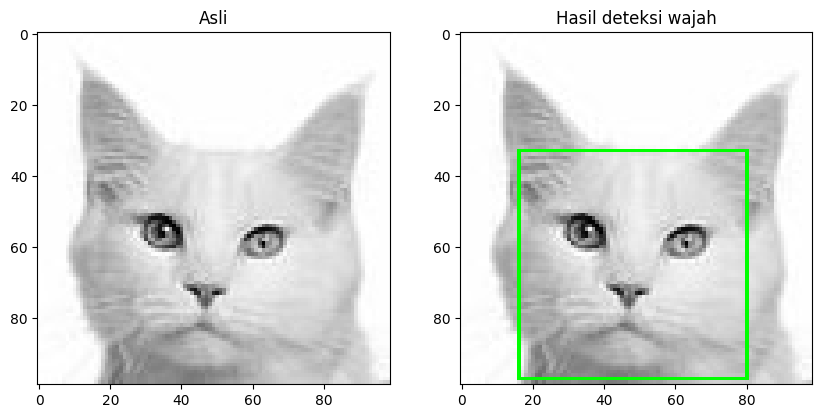

animal.jpg -> jumlah wajah: 1


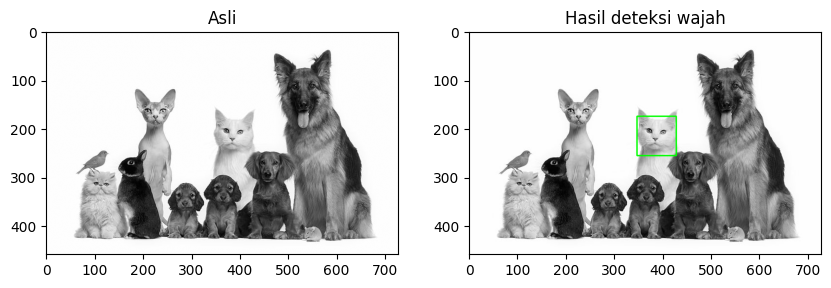

bahrain-template.jpg -> jumlah wajah: 0


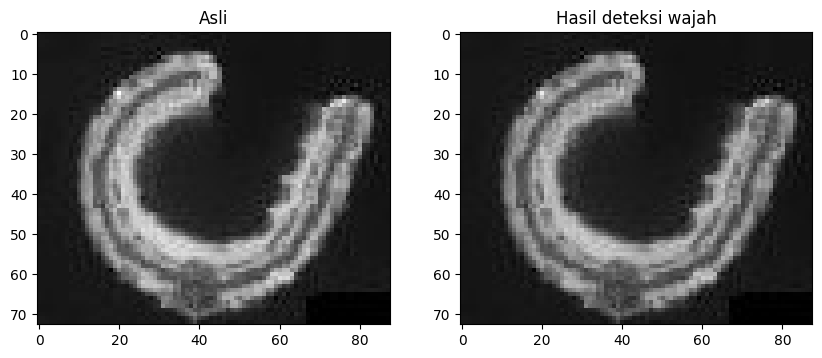

bahrain.jpg -> jumlah wajah: 0


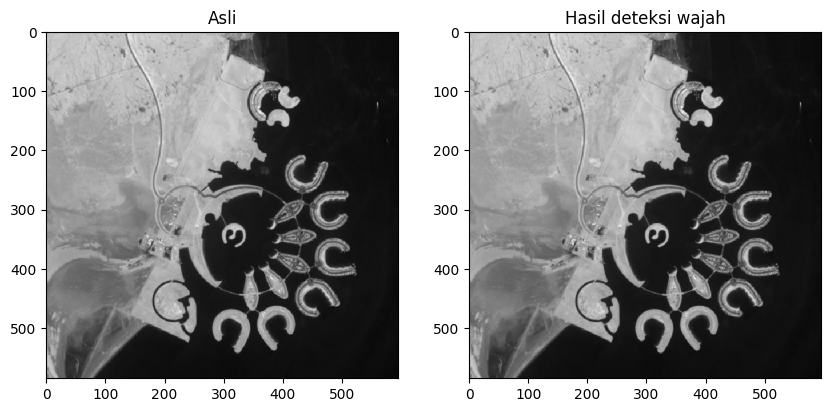

car-park.jpg -> jumlah wajah: 0


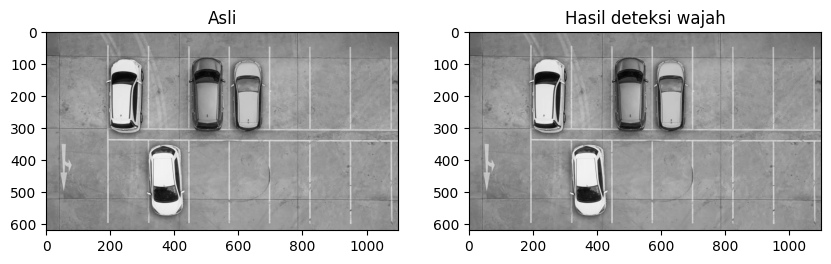

cat-and-rabbit.jpg -> jumlah wajah: 0


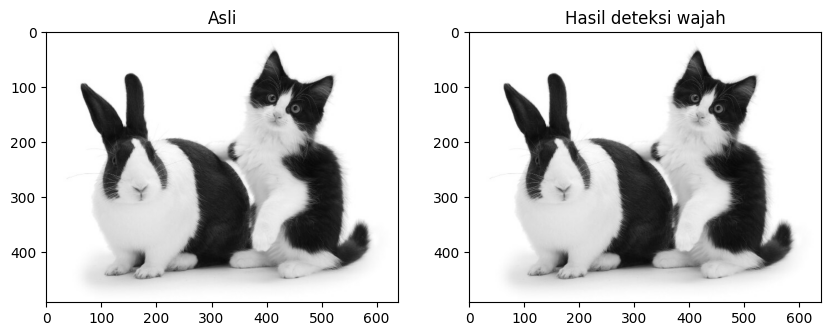

cat-template.jpg -> jumlah wajah: 0


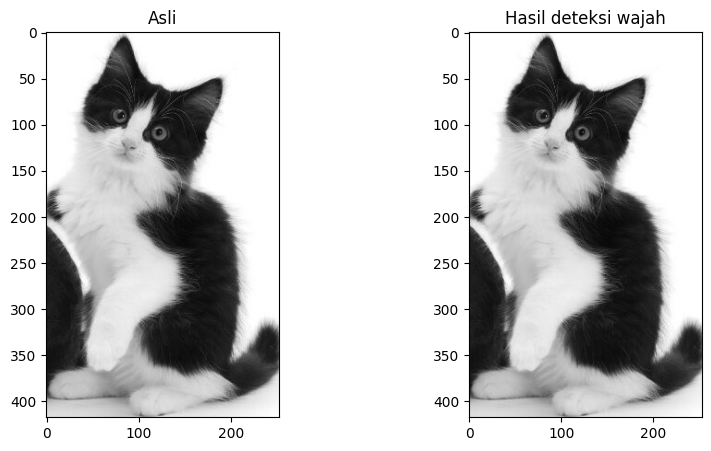

cat2_templatejpg.jpg -> jumlah wajah: 1


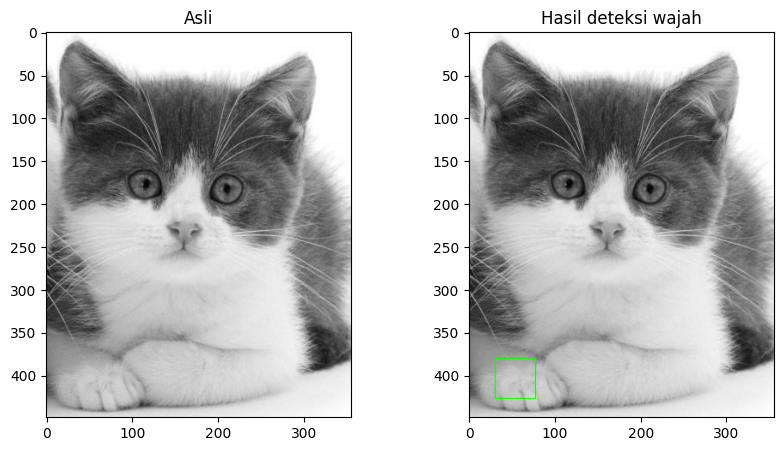

cats_and_bunnies.jpg -> jumlah wajah: 0


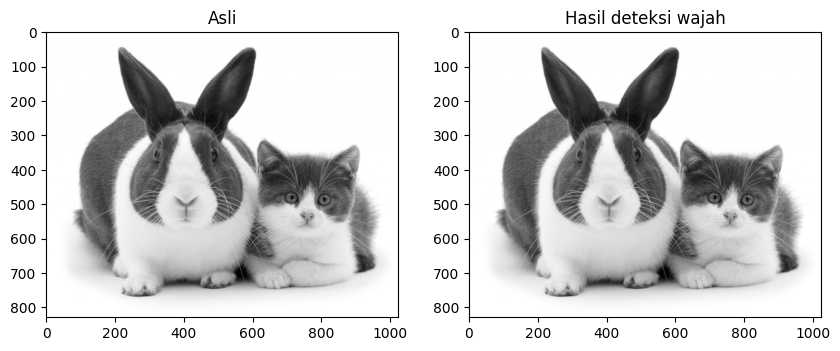

chess-board.jpg -> jumlah wajah: 0


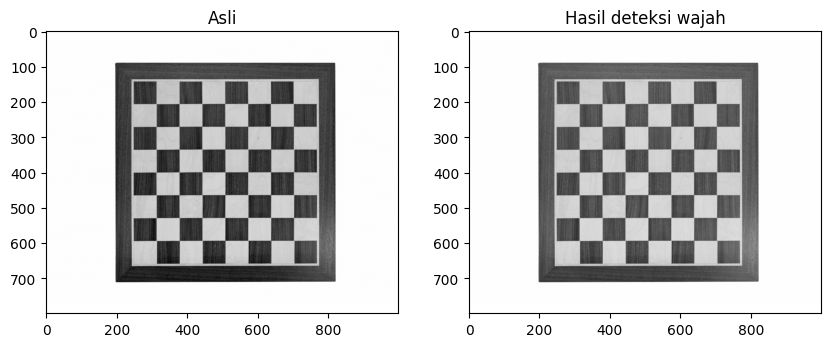

couple.jpg -> jumlah wajah: 0


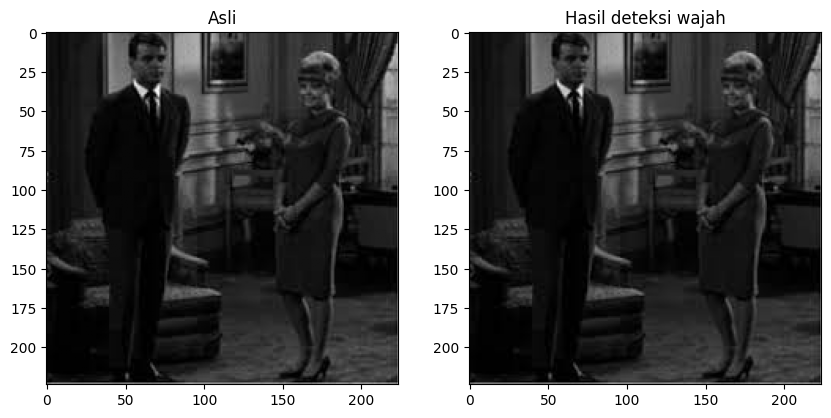

dog.jpg -> jumlah wajah: 1


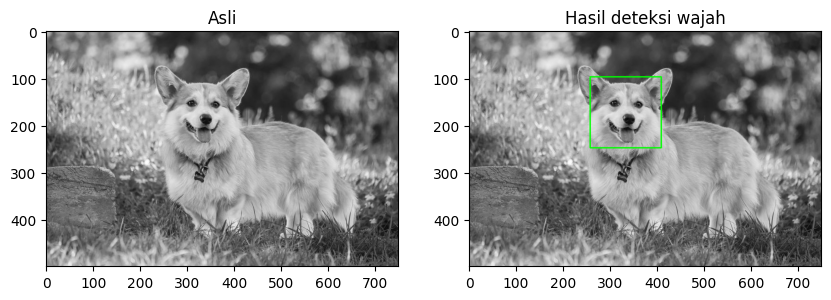

galaxy.jpg -> jumlah wajah: 0


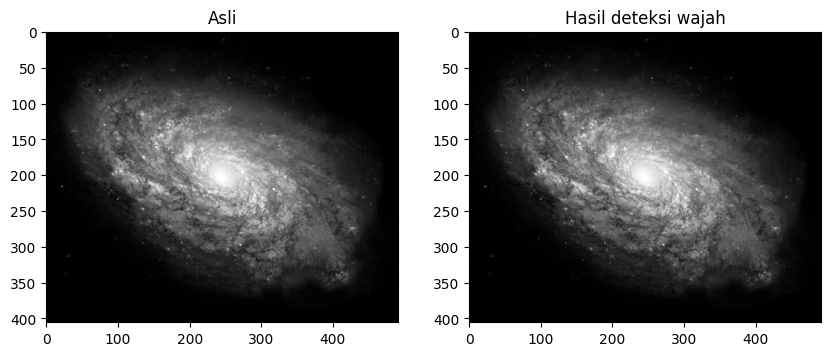

houses.jpg -> jumlah wajah: 0


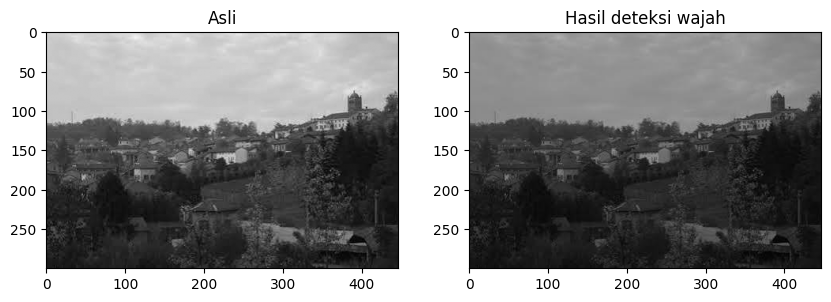

jokowi.jpg -> jumlah wajah: 1


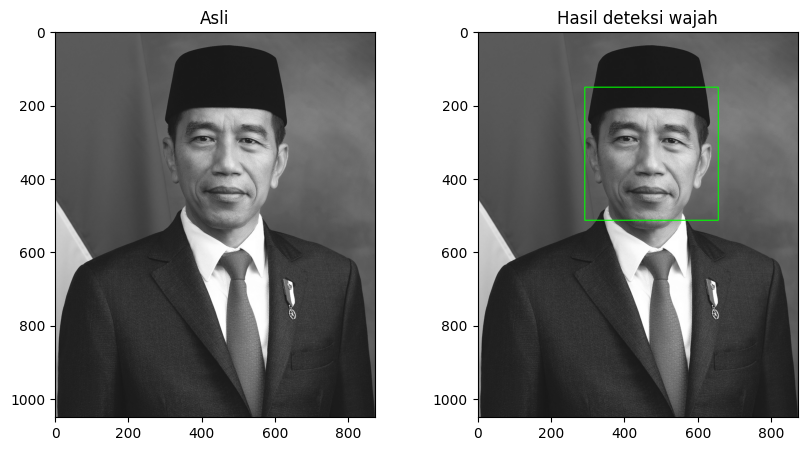

kartini.jpg -> jumlah wajah: 1


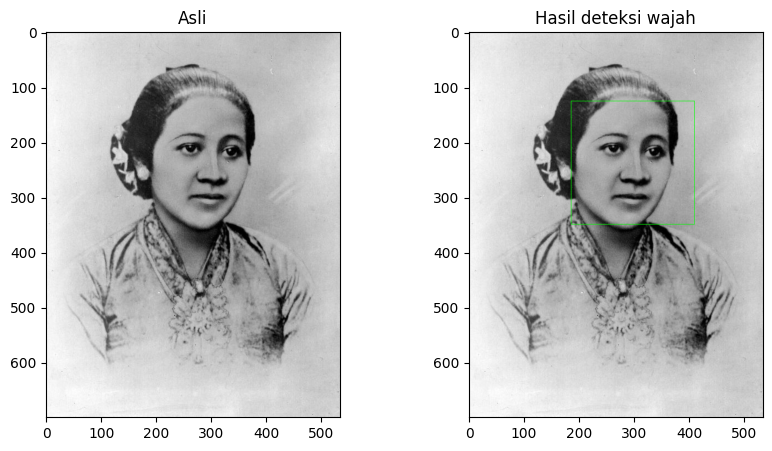

kucing.jpg -> jumlah wajah: 0


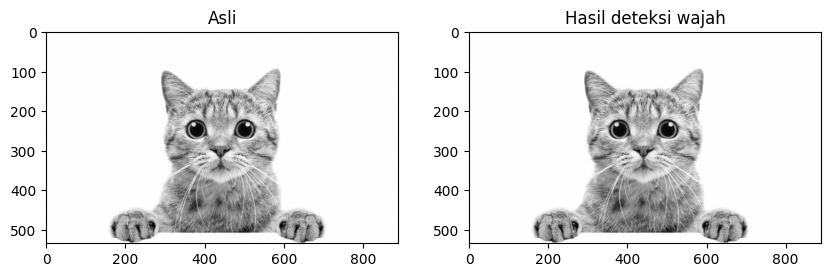

laptop.jpg -> jumlah wajah: 0


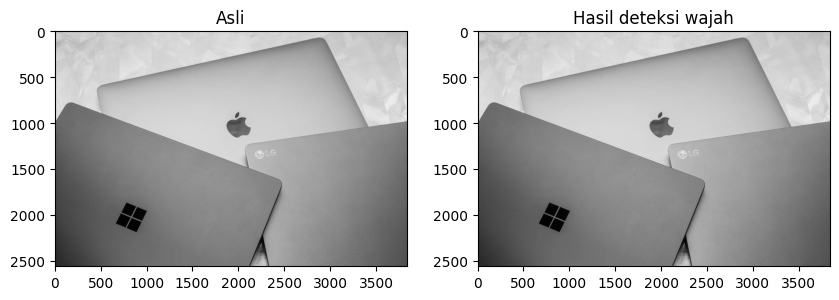

malam.jpg -> jumlah wajah: 0


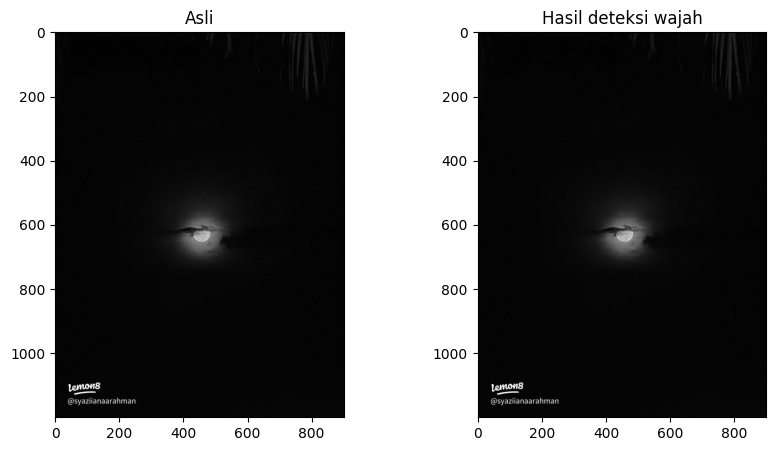

mask.png -> jumlah wajah: 5


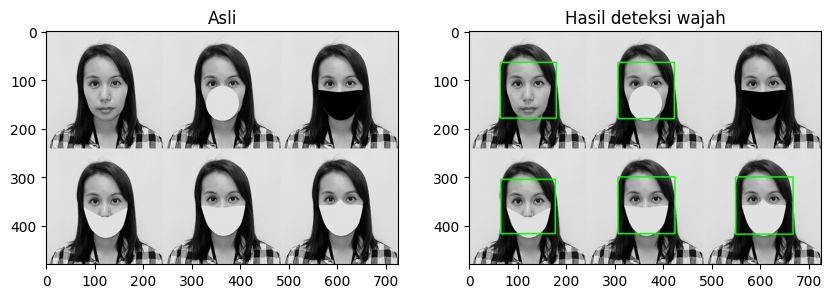

mjordan.jpg -> jumlah wajah: 1


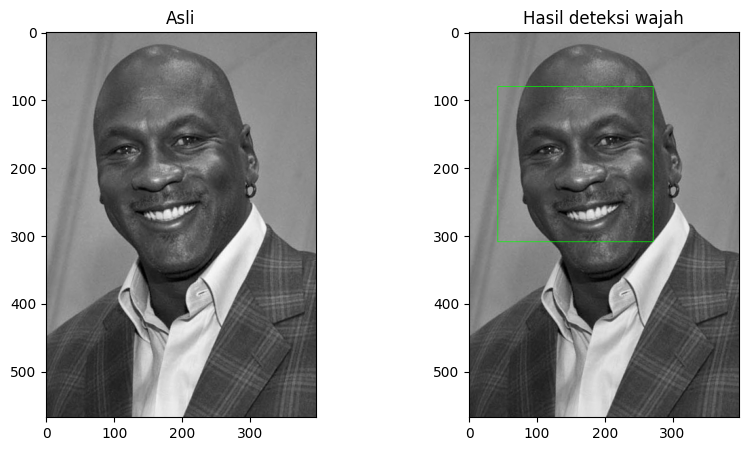

mycat.jpg -> jumlah wajah: 0


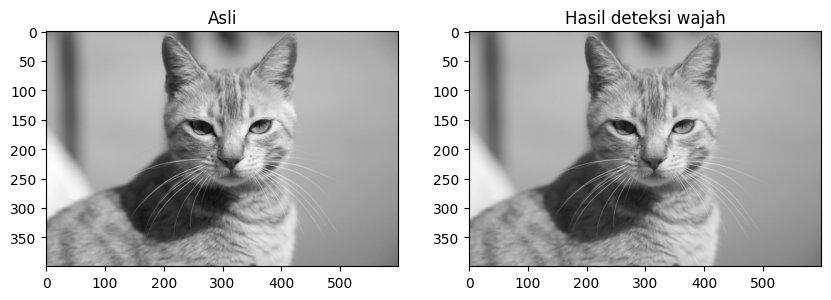

paprika.jpg -> jumlah wajah: 0


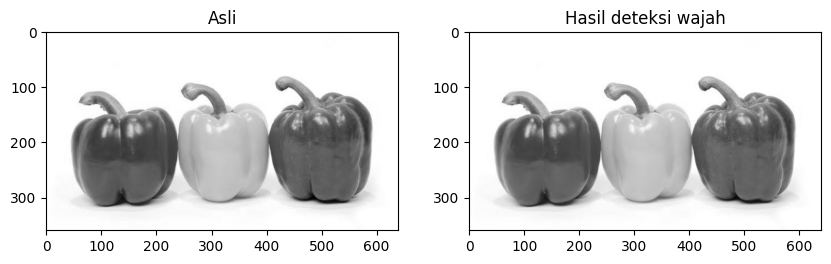

parking-lot-cars.jpg -> jumlah wajah: 0


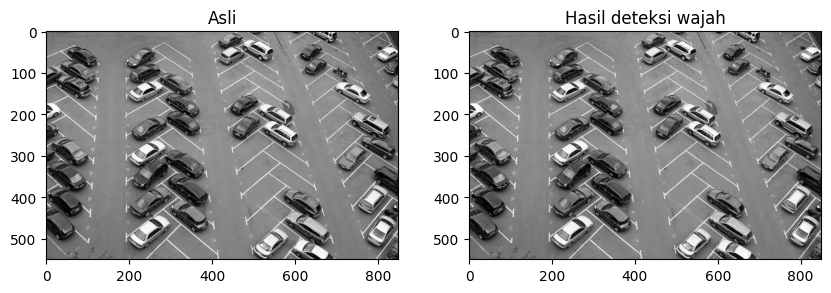

people.jpg -> jumlah wajah: 9


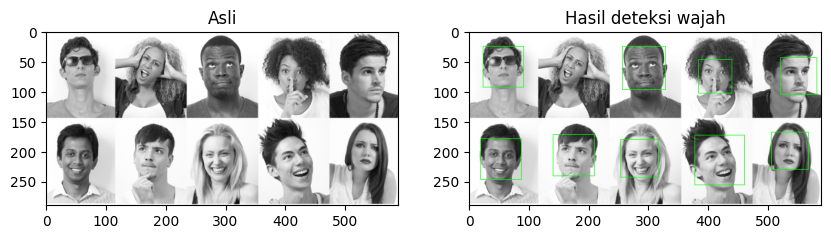

prabowo.jpg -> jumlah wajah: 1


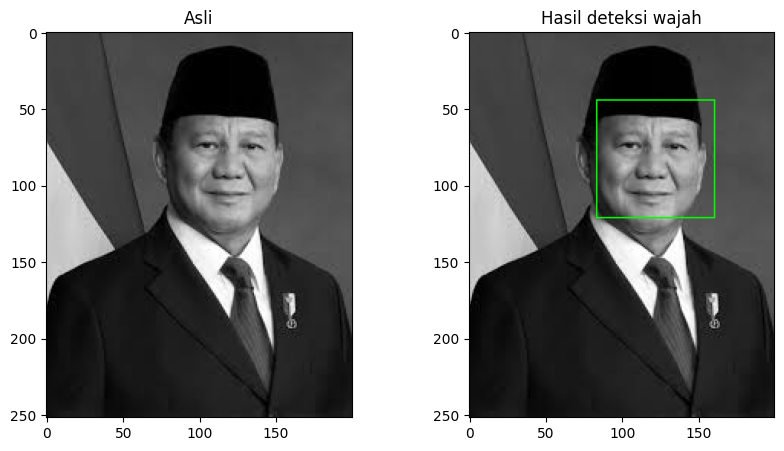

sky.jpg -> jumlah wajah: 0


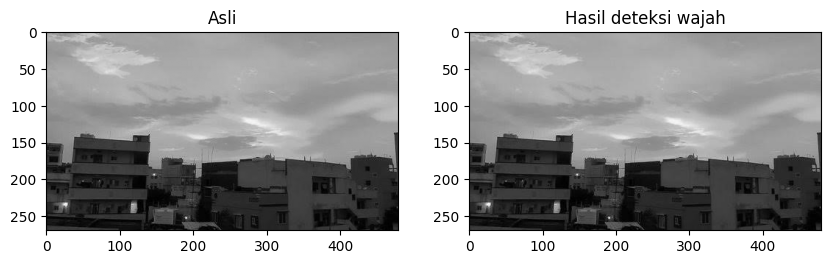

smile.png -> jumlah wajah: 0


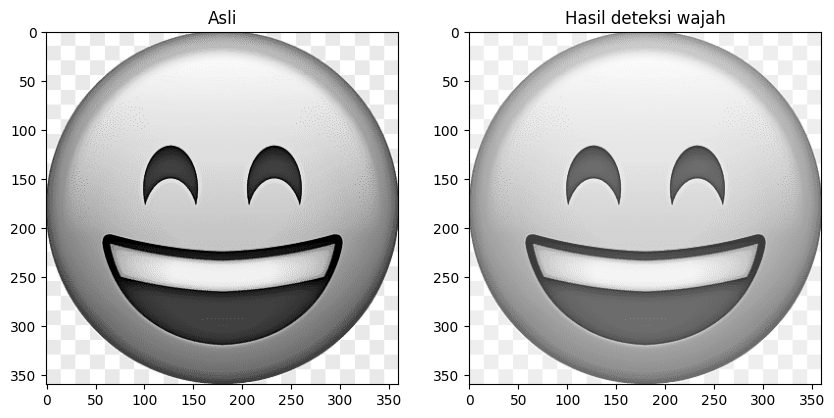

solvayconf.jpg -> jumlah wajah: 28


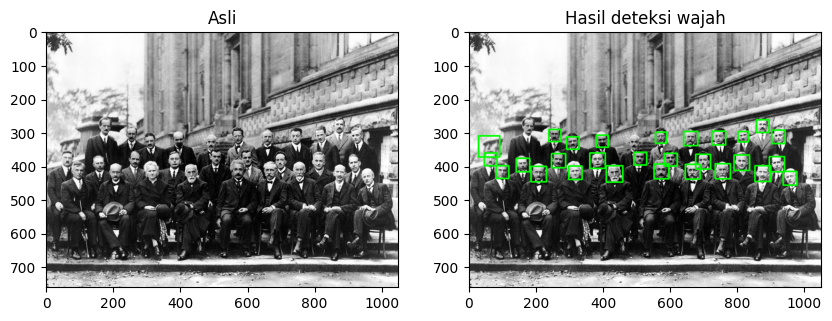

sudoku.jpg -> jumlah wajah: 0


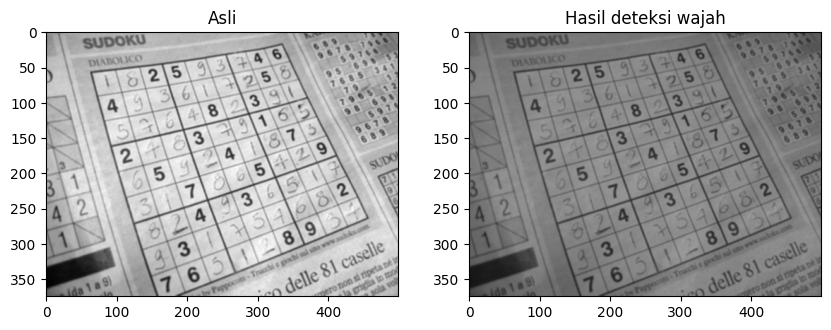

In [53]:
# gambar untuk feature matching tidak diikutkan
lewati = ('reeses', 'cereal', 'ktm')

for f in daftar:
    nama = os.path.basename(f).lower()
    if any(k in nama for k in lewati):
        continue
    gray = baca_gray(f)
    hasil = cv.cvtColor(gray, cv.COLOR_GRAY2RGB)
    wajah = deteksi(gray, cascade_wajah)
    tebal = max(1, gray.shape[1] // 300)
    for (x, y, w, h) in wajah:
        cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), tebal)
    print(os.path.basename(f), '-> jumlah wajah:', len(wajah))
    pasangan(gray, hasil, 'Asli', 'Hasil deteksi wajah', ukuran=(10, 5))

### 9. Deteksi wajah kucing
Haar cascade bawaan OpenCV: `haarcascade_frontalcatface.xml` (ada juga versi `_extended`).

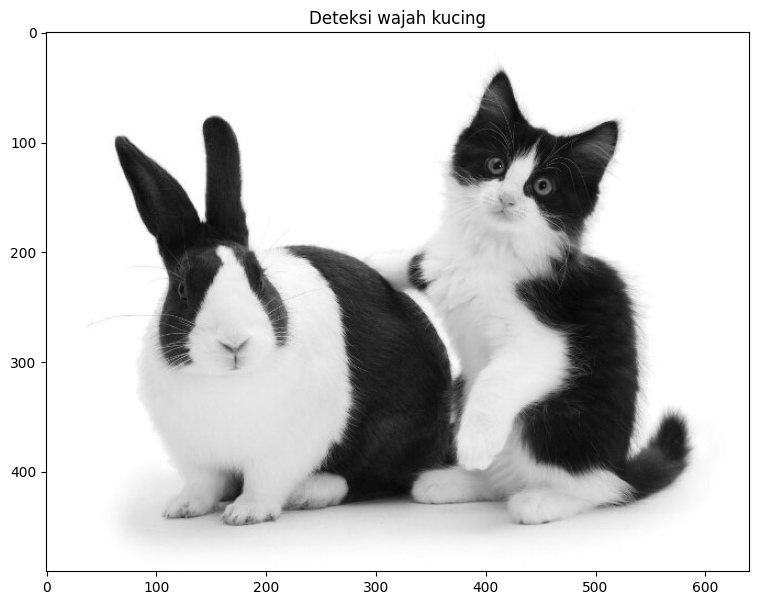

In [54]:
gray_kucing = baca_gray(cari_gambar('cat', 'kucing'))
hasil = gray_kucing.copy()

wajah_kucing = ()
for nama_xml in ['haarcascade_frontalcatface.xml', 'haarcascade_frontalcatface_extended.xml']:
    cascade_kucing = muat_cascade(nama_xml)
    wajah_kucing = deteksi(gray_kucing, cascade_kucing, scaleFactor=1.05, minNeighbors=3, minSize=(60, 60))
    if len(wajah_kucing) > 0:
        print('Terdeteksi dengan', nama_xml)
        break

for (x, y, w, h) in wajah_kucing:
    cv.rectangle(hasil, (x, y), (x + w, y + h), (255, 255, 255), 3)

tampil(hasil, 'Deteksi wajah kucing', ukuran=(10, 7))

### 10. Eyes detection pada wajah Pak Prabowo

In [49]:
prabowo = baca_gray(cari_gambar('prabowo'))
cascade_mata = muat_cascade('haarcascade_eye.xml')
hasil = prabowo.copy()

# mata dicari di dalam area wajah supaya lebih akurat
for (fx, fy, fw, fh) in deteksi(prabowo, cascade_wajah):
    roi = prabowo[fy:fy + fh, fx:fx + fw]
    for (ex, ey, ew, eh) in deteksi(roi, cascade_mata, 1.1, 5):
        cv.rectangle(hasil, (fx + ex, fy + ey), (fx + ex + ew, fy + ey + eh), (255, 255, 255), 1)

tampil(hasil, 'Eyes detection', ukuran=(8, 10))

FileNotFoundError: Tidak ada file dengan kata kunci ('prabowo',). Cek daftar di atas.

### 11. Deteksi senyuman pada gambar people
Senyum dicari pada separuh bawah area wajah memakai `haarcascade_smile.xml`.

In [ ]:
people = baca_rgb(cari_gambar('people'))
gray_people = cv.cvtColor(people, cv.COLOR_RGB2GRAY)
cascade_senyum = muat_cascade('haarcascade_smile.xml')

hasil = people.copy()
for (fx, fy, fw, fh) in deteksi(gray_people, cascade_wajah):
    cv.rectangle(hasil, (fx, fy), (fx + fw, fy + fh), (0, 0, 255), 3)
    roi = gray_people[fy + fh // 2: fy + fh, fx: fx + fw]          # separuh bawah wajah
    for (sx, sy, sw, sh) in cascade_senyum.detectMultiScale(roi, scaleFactor=1.7, minNeighbors=22, minSize=(25, 25)):
        cv.rectangle(hasil, (fx + sx, fy + fh // 2 + sy), (fx + sx + sw, fy + fh // 2 + sy + sh), (0, 255, 0), 3)

tampil(hasil, 'Deteksi senyuman (hijau) pada wajah (biru)', ukuran=(12, 8))

### 12. Face Tracking (kamera) di Google Colab
Colab tidak bisa membuka kamera secara langsung, jadi dipakai JavaScript. Izinkan akses kamera di browser. Klik video atau tulisan merah untuk berhenti.

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode, b64encode
import PIL, io, html

def video_stream():
    js = Javascript('''
    var video;
    var div = null;
    var stream;
    var captureCanvas;
    var imgElement;
    var labelElement;
    var pendingResolve = null;
    var shutdown = false;

    function removeDom() {
       stream.getVideoTracks()[0].stop();
       video.remove();
       div.remove();
       video = null;
       div = null;
       stream = null;
       imgElement = null;
       captureCanvas = null;
       labelElement = null;
    }

    function onAnimationFrame() {
      if (!shutdown) {
        window.requestAnimationFrame(onAnimationFrame);
      }
      if (pendingResolve) {
        var result = "";
        if (!shutdown) {
          captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
          result = captureCanvas.toDataURL('image/jpeg', 0.8)
        }
        var lp = pendingResolve;
        pendingResolve = null;
        lp(result);
      }
    }

    async function createDom() {
      if (div !== null) {
        return stream;
      }
      div = document.createElement('div');
      div.style.border = '2px solid black';
      div.style.padding = '3px';
      div.style.width = '100%';
      div.style.maxWidth = '600px';
      document.body.appendChild(div);

      const modelOut = document.createElement('div');
      modelOut.innerHTML = "<span>Status:</span>";
      labelElement = document.createElement('span');
      labelElement.innerText = 'No data';
      labelElement.style.fontWeight = 'bold';
      modelOut.appendChild(labelElement);
      div.appendChild(modelOut);

      video = document.createElement('video');
      video.style.display = 'block';
      video.width = div.clientWidth - 6;
      video.setAttribute('playsinline', '');
      video.onclick = () => { shutdown = true; };
      stream = await navigator.mediaDevices.getUserMedia({video: { facingMode: "user"}});
      div.appendChild(video);

      imgElement = document.createElement('img');
      imgElement.style.position = 'absolute';
      imgElement.style.zIndex = 1;
      imgElement.onclick = () => { shutdown = true; };
      div.appendChild(imgElement);

      const instruction = document.createElement('div');
      instruction.innerHTML =
          '<span style="color: red; font-weight: bold;">' +
          'Klik di sini atau pada video untuk berhenti</span>';
      div.appendChild(instruction);
      instruction.onclick = () => { shutdown = true; };

      video.srcObject = stream;
      await video.play();

      captureCanvas = document.createElement('canvas');
      captureCanvas.width = 640;
      captureCanvas.height = 480;
      window.requestAnimationFrame(onAnimationFrame);
      return stream;
    }

    async function stream_frame(label, imgData) {
      if (shutdown) {
        removeDom();
        shutdown = false;
        return '';
      }
      var preCreate = Date.now();
      stream = await createDom();
      var preShow = Date.now();
      if (label != "") {
        labelElement.innerHTML = label;
      }
      if (imgData != "") {
        var videoRect = video.getClientRects()[0];
        imgElement.style.top = videoRect.top + "px";
        imgElement.style.left = videoRect.left + "px";
        imgElement.style.width = videoRect.width + "px";
        imgElement.style.height = videoRect.height + "px";
        imgElement.src = imgData;
      }
      var preCapture = Date.now();
      var result = await new Promise(function(resolve, reject) {
        pendingResolve = resolve;
      });
      shutdown = false;
      return {'create': preShow - preCreate,
              'show': preCapture - preShow,
              'capture': Date.now() - preCapture,
              'img': result};
    }
    ''')
    display(js)

def video_frame(label, bbox):
    return eval_js('stream_frame("{}", "{}")'.format(label, bbox))

def js_to_image(js_reply):
    # data URL dari JavaScript -> gambar OpenCV (BGR)
    image_bytes = b64decode(js_reply.split(',')[1])
    jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
    return cv.imdecode(jpg_as_np, flags=1)

def bbox_to_bytes(bbox_array):
    # overlay RGBA (kotak wajah) -> data URL PNG
    bbox_PIL = PIL.Image.fromarray(bbox_array, 'RGBA')
    iobuf = io.BytesIO()
    bbox_PIL.save(iobuf, format='png')
    return 'data:image/png;base64,{}'.format(str(b64encode(iobuf.getvalue()), 'utf-8'))

In [ ]:
# jalankan face tracking
video_stream()
label_html = 'Mendeteksi wajah...'
bbox = ''

while True:
    js_reply = video_frame(label_html, bbox)
    if not js_reply:
        break

    frame = js_to_image(js_reply['img'])
    gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)

    bbox_array = np.zeros([480, 640, 4], dtype=np.uint8)
    for (x, y, w, h) in deteksi(gray, cascade_wajah, 1.1, 5):
        cv.rectangle(bbox_array, (x, y), (x + w, y + h), (255, 0, 0, 255), 2)

    bbox_array[:, :, 3] = (bbox_array.max(axis=2) > 0).astype(np.uint8) * 255
    bbox = bbox_to_bytes(bbox_array)

### 13. Blurring pada wajah yang terdeteksi
Memakai `cv.medianBlur` pada area wajah.

In [ ]:
foto = baca_gray(cari_gambar('jordan', 'michael', 'mj'))   # gambar wajah pria berjas; ganti kata kunci bila perlu
hasil = foto.copy()

for (x, y, w, h) in deteksi(foto, cascade_wajah):
    roi = hasil[y:y + h, x:x + w]
    hasil[y:y + h, x:x + w] = cv.medianBlur(roi, 51)     # ukuran kernel harus ganjil

tampil(hasil, 'Wajah di-blur', ukuran=(7, 9))

### 14. Mengolah gambar KTM masing-masing
Siapkan 2 gambar di folder `BASE`: foto KTM sendiri dan foto yang berisi KTM bersama barang lain.

In [ ]:
FILE_KTM       = path('ktm.jpg')          # a. gambar KTM
FILE_KTM_SCENE = path('ktm_scene.jpg')    # c. gambar KTM bersama barang lain

# a. tampilkan KTM
ktm = baca_rgb(FILE_KTM)
tampil(ktm, 'KTM', ukuran=(9, 6))

In [ ]:
# b. tampilkan foto KTM (deteksi wajah, lalu crop dengan margin agar rambut/hijab dan bahu ikut)
gray_ktm = cv.cvtColor(ktm, cv.COLOR_RGB2GRAY)
wajah = deteksi(gray_ktm, cascade_wajah, scaleFactor=1.05, minNeighbors=3)
print('Wajah terdeteksi:', len(wajah))

x, y, w, h = max(wajah, key=lambda r: r[2] * r[3])     # ambil wajah terbesar
H, W = ktm.shape[:2]
x1, x2 = max(0, x - int(0.45 * w)), min(W, x + w + int(0.45 * w))
y1, y2 = max(0, y - int(0.60 * h)), min(H, y + h + int(0.80 * h))

foto_ktm = ktm[y1:y2, x1:x2]
tampil(foto_ktm, 'FOTO KTM', ukuran=(5, 5))

In [ ]:
# c. deteksi obyek KTM pada gambar berisi barang lain dengan Feature Matching (SIFT + ratio test + homography)
template = cv.imread(FILE_KTM, 0)
scene    = cv.imread(FILE_KTM_SCENE)
if template is None or scene is None:
    raise FileNotFoundError('Cek FILE_KTM dan FILE_KTM_SCENE')
scene_gray = cv.cvtColor(scene, cv.COLOR_BGR2GRAY)

sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(template, None)
kp2, des2 = sift.detectAndCompute(scene_gray, None)

bf = cv.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)
good = [m for m, n in (p for p in matches if len(p) == 2) if m.distance < 0.75 * n.distance]
print('good match:', len(good))

hasil = cv.cvtColor(scene, cv.COLOR_BGR2RGB)
if len(good) >= 10:
    src = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    M, mask = cv.findHomography(src, dst, cv.RANSAC, 5.0)

    th_, tw_ = template.shape
    sudut = np.float32([[0, 0], [0, th_ - 1], [tw_ - 1, th_ - 1], [tw_ - 1, 0]]).reshape(-1, 1, 2)
    kotak = cv.perspectiveTransform(sudut, M)
    cv.polylines(hasil, [np.int32(kotak)], True, (0, 255, 0), 8)
else:
    print('Good match kurang dari 10, KTM tidak ditemukan')

garis_cocok = cv.drawMatches(cv.cvtColor(cv.imread(FILE_KTM), cv.COLOR_BGR2RGB), kp1,
                             cv.cvtColor(scene, cv.COLOR_BGR2RGB), kp2, good[:50], None, flags=2)
tampil(garis_cocok, 'Pencocokan fitur', ukuran=(14, 6))
tampil(hasil, 'Hasil deteksi KTM', ukuran=(10, 8))

## D3. Tugas Pengayaan: Pengenalan Karakter KTM dengan CNN

Siapkan struktur folder (crop karakter satu per satu memakai image editor):

```
dataset/training/0 ... 9     (satu subfolder per karakter, isi banyak gambar)
dataset/testing/<nama_folder>/   (karakter KTM Anda berurutan, mis. 01.png, 02.png, ...)
```

In [ ]:
# pindah ke folder kerja D3 (berisi folder dataset); sesuaikan
os.chdir('/content/drive/MyDrive/Polinema/Kuliah/PCVK/D3')
print(os.getcwd(), os.listdir('.'))

### D3.1 Persiapan data training

In [ ]:
import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = "dataset/training"      # satu subfolder per karakter: 0..9, A..Z
width, height = 100, 100

dirs = sorted(os.listdir(DATADIR))        # daftar nama kelas
training_data = []

for char_name in dirs:
    path_kelas = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path_kelas), desc=char_name):
        try:
            img_array = cv2.imread(os.path.join(path_kelas, img), cv2.IMREAD_GRAYSCALE)
            new_array = cv2.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X,    open("X.pickle", "wb"))
pickle.dump(Y,    open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data :", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

### D3.2 Training data (CNN)

In [ ]:
import pickle
from keras.layers import (Input, Conv2D, MaxPooling2D,
                          Flatten, Dense, ZeroPadding2D)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]         # diambil dari data, tidak ditulis tetap

inputs     = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten   = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64,  activation='relu')(fc_layer)
outputs  = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save('anpr.keras')

print("akurasi training :", riwayat.history['accuracy'][-1])
print("akurasi validasi :", riwayat.history['val_accuracy'][-1])

### D3.3 Testing pengenalan karakter KTM

In [ ]:
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = "dataset/testing"
width, height = 100, 100

model = tf.keras.models.load_model("anpr.keras")
dirs  = pickle.load(open("kelas.pickle", "rb"))    # urutan kelas saat training

for car in sorted(os.listdir(data_dir_testing)):
    temp = ""
    folder = os.path.join(data_dir_testing, car)
    for char_img in sorted(os.listdir(folder)):
        img_array = cv2.imread(os.path.join(folder, char_img),
                               cv2.IMREAD_GRAYSCALE)
        new_array = cv2.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]
    print("folder name: {} no: {}".format(car, temp))